## Test Day with pretty ugly data

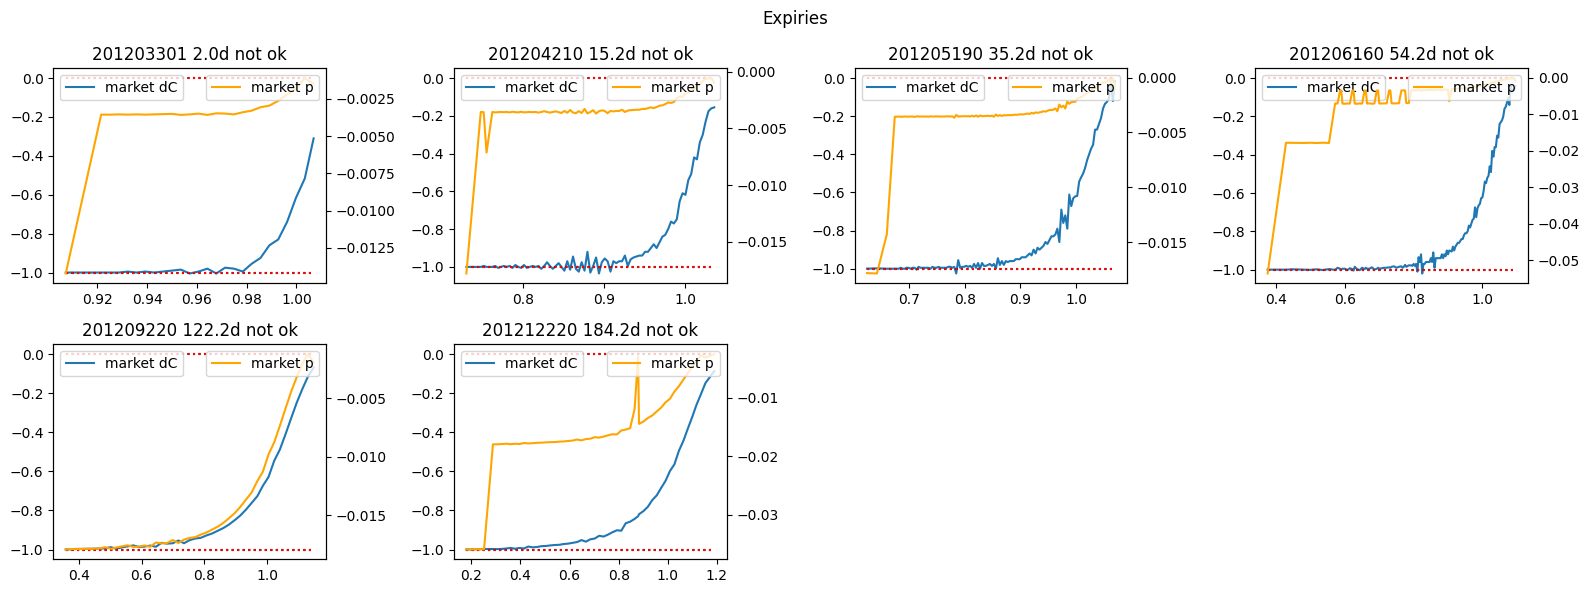

00: SPX 2012-03-28: Generating arb-free price surface.
01:   SPX 2012-03-28: Generated 6 linear arbitrage-free expiries with extended strikes from 6 market expiries. This took 0.15s.              
01:   SPX 2012-03-28: Finding linear arbitrage-free mid prices accross the entire surface of 257 strikes with a minimum strike distance of 0.00356... done. This took 0.049s.
00: SPX 2012-03-28: generated arbitrage-free price surface. Dropped 0 expiries and 209 strikes of the remaining expiries. This took 0.24s.


,spot,spot_prev,date,ticker,call_symbol,put_symbol,call_opt_id,put_opt_id,is_american,is_am,...,pure_fit1_gamma,pure_fit1_vega,pure_fit1_theta,fitX_vol,pure_fitX_price,pure_fitX_delta,pure_fitX_dk,pure_fitX_gamma,pure_fitX_vega,pure_fitX_theta
0,1405.540039,1412.52002,2012-03-28,SPX,SPXQ 120330C1275000,SPXQ 120330P1275000,80952564,80952575,False,False,...,0.100723,0.000282,0.006271,0.010000,0.092697,1.000000,-1.000000,0.000000,0.000000,0.000000
1,1405.540039,1412.52002,2012-03-28,SPX,SPXQ 120330C1295000,SPXQ 120330P1295000,81365841,81365893,False,False,...,0.380318,0.001049,0.022975,0.322455,0.078482,0.997874,-0.997674,0.233245,0.000597,0.012126
2,1405.540039,1412.52002,2012-03-28,SPX,SPXQ 120330C1300000,SPXQ 120330P1300000,53101831,53101834,False,False,...,0.460285,0.001240,0.026500,0.320656,0.074933,0.996927,-0.996649,0.327297,0.000833,0.016826
3,1405.540039,1412.52002,2012-03-28,SPX,SPXQ 120330C1305000,SPXQ 120330P1305000,81365842,81365894,False,False,...,0.552388,0.001448,0.030140,0.315529,0.071384,0.995944,-0.995594,0.426738,0.001069,0.021243
4,1405.540039,1412.52002,2012-03-28,SPX,SPXQ 120330C1310000,SPXQ 120330P1310000,81365843,81365895,False,False,...,0.656948,0.001671,0.033743,0.308859,0.067836,0.994841,-0.994417,0.540400,0.001325,0.025775
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,1405.540039,1412.52002,2012-03-28,SPX,SPX 121222C1525000,SPX 121222P1525000,80983783,80983789,False,True,...,2.518974,0.266916,0.026468,0.144355,0.016505,0.240799,-0.204075,2.523438,0.266265,0.026292
450,1405.540039,1412.52002,2012-03-28,SPX,SPX 121222C1550000,SPX 121222P1550000,45577453,34919208,False,True,...,2.293419,0.233880,0.022320,0.138903,0.011861,0.191321,-0.160649,2.294810,0.232995,0.022138
451,1405.540039,1412.52002,2012-03-28,SPX,SPX 121222C1575000,SPX 121222P1575000,80983784,80983790,False,True,...,2.009719,0.197227,0.018113,0.133664,0.008199,0.146438,-0.121785,2.007748,0.196161,0.017935
452,1405.540039,1412.52002,2012-03-28,SPX,SPX 121222C1600000,SPX 121222P1600000,45998681,34919210,False,True,...,1.692185,0.160798,0.014299,0.129096,0.005495,0.108282,-0.089137,1.684502,0.158954,0.014037


In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2012, 3, 28), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )

    with figure("Expiries", row_size=3, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = (bids + asks) / 2.

            dC = np.diff( mids, prepend=1. ) / np.diff( strikes, prepend=0. )
            p  = np.diff( mids, append=0.) 

            ok = np.all(p>=-1E-6) and abs(np.sum(p)-1) < 1E-6 and abs(p@strikes-1.) < 1E-6
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d {'ok' if ok else 'not ok'}")
            ax.plot(strikes, dC, label="market dC")
            ax.plot(strikes, strikes*0-1., ":", color="black")
            ax.plot(strikes, strikes*0, ":", color="black")
            ax.legend(loc="upper left")
            ax2 = ax.twinx()
            ax2.plot(strikes, p, label="market p", color="orange")
            ax.plot(strikes, strikes*0-1., ":", color="red")
            ax.plot(strikes, strikes*0, ":", color="red")
            ax2.legend(loc="upper right")

    """
    mask = enr_day['expiry_id'] == BAD_UID
    tte_y = enr_day['tte_y'][ mask].iloc[0]
    expiry = enr_day['expiry'][ mask].iloc[0]
    is_am = enr_day['is_am'][ mask].iloc[0]
    strikes = enr_day['pure_strike'][mask].to_numpy()
    bids = enr_day['pure_bid_price'][mask].to_numpy()
    asks = enr_day['pure_ask_price'][mask].to_numpy()
    mids = (bids + asks) / 2.
    intr = np.maximum( 0., 1. - strikes )
    
    with figure(f"{expiry} {'am' if is_am else 'pm'}", row_size=10, col_size=14, columns=1) as fig:
        ax = fig.add_subplot()

        ax.plot(strikes, mids-intr, ".-", color="orange", label="mid")
        ax.plot(strikes, bids-intr,"^:", color="green", label="bid")
        ax.plot(strikes, asks-intr, "v:", color="red", label="ask")
        ax.legend(loc="upper left")
    """


    arb_free = MkArbFree(timeout_seconds_expiry=500)
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()